# Mbappé: The Problem?

## From an individual paradox to a collective diagnosis

**Project by Sofia Jordan**  
**Methods:** exploratory data analysis, normalization, correlation analysis, PCA, clustering, regression, counterfactual similarity and sensitivity analysis

Kylian Mbappé's first season at Real Madrid creates a paradox. 

Individually : 31 goals in 34 LaLiga matches and 44 goals in 59 matches in all competitions, winning the Pichichi and the European Golden Boot. 

Collectively : Real Madrid, who had just won two of the last three Champions League and two of the last three LaLiga's titles, won none of the three major trophies considered in this study: LaLiga, the UEFA Champions League or the Copa del Rey, since Mbappé arrival.

This led many to believe that it couldn't be a coincidence, and that Mbappé, despite his individual performances, as the one killing the team winnings.

This is what this project will try to break down

## *Did Mbappé make Real Madrid worse,or did his arrival coincide with a more rooted and structural problem elsewhere in the team?*

The analysis does not select a culprit in advance. It follows the evidence from output, to team balance, to hidden performance dimensions, and finally to competing explanations.

## The analytical journey

1. Import and audit the data
2. Establish the individual–collective paradox
3. Compare the team before and after Mbappé
4. Normalize the indicators and construct an overall performance score
5. Explore correlations between attack, defence and results
6. Use Principal Component Analysis (PCA) to uncover latent performance dimensions
7. Cluster Real Madrid seasons into tactical-performance profiles
8. Run explanatory regressions and historical similarity analysis
9. Test whether the conclusion depends on arbitrary index weights
10. Produce an evidence-based verdict

Each method has a purpose. PCA is not included merely to look technical: it tests whether 2024/25 moved toward a distinct underlying profile—particularly weaker collective control and defence.

## Scope and causal warning

The central comparison is:

- **2023/24:** the final pre-Mbappé season; Real Madrid won LaLiga and the Champions League.
- **2024/25:** Mbappé's first season; no LaLiga, Champions League or Copa del Rey title.

Official references: [Mbappé joins Real Madrid](https://www.realmadrid.com/en-US/news/football/first-team/latest-news/mbappe-nuevo-jugador-del-real-madrid-03-06-2024), [Kroos retirement announcement](https://www.realmadrid.com/en-US/news/club/announcements/comunicado-oficial-toni-kroos-21-05-2024), [Carvajal medical report](https://www.realmadrid.com/en-US/news/football/first-team/medical-reports/parte-medico-de-carvajal-06-10-2024), and [Militão medical report](https://www.realmadrid.com/en-US/news/football/first-team/medical-reports/parte-medico-09-11-2024).

# I. Importing libraries and defining the visual identity

In [4]:
from __future__ import annotations

import io
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, r2_score, silhouette_score
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.preprocessing import MinMaxScaler, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

COLORS = {
    "ink": "#111827",
    "gold": "#D4AF37",
    "grey": "#9CA3AF",
    "light": "#E5E7EB",
    "red": "#DC2626",
    "green": "#059669",
    "blue": "#2563EB",
    "purple": "#7C3AED",
}

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams.update({
    "figure.figsize": (12, 6.5),
    "axes.titleweight": "bold",
    "axes.titlesize": 18,
    "axes.labelsize": 12,
    "font.family": "DejaVu Sans",
})

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42

# II. Importing and understanding the datasets

## 1. Historical team dataset

The core dataset contains one observation per completed Real Madrid LaLiga season from 2014/15 to 2024/25. 

The raw variables are intentionally simple and auditable: matches, wins, draws, losses, goals scored, goals conceded, points, league position and major titles. Derived indicators are calculated in the notebook.

League match data are available under the PDDL from the [football-datasets repository](https://github.com/datasets/football-datasets/tree/main/datasets/la-liga). The 2023/24 and 2024/25 team and player figures can also be cross-checked on FBref's Real Madrid season pages.

In [5]:
season_records = [
    ["2014/15", 38, 30, 2, 6, 118, 38, 92, 2, 0, "Ancelotti", 0],
    ["2015/16", 38, 28, 6, 4, 110, 34, 90, 2, 1, "Benitez_Zidane", 0],
    ["2016/17", 38, 29, 6, 3, 106, 41, 93, 1, 2, "Zidane", 0],
    ["2017/18", 38, 22, 10, 6, 94, 44, 76, 3, 1, "Zidane", 0],
    ["2018/19", 38, 21, 5, 12, 63, 46, 68, 3, 0, "Multiple", 0],
    ["2019/20", 38, 26, 9, 3, 70, 25, 87, 1, 1, "Zidane", 0],
    ["2020/21", 38, 25, 9, 4, 67, 28, 84, 2, 0, "Zidane", 0],
    ["2021/22", 38, 26, 8, 4, 80, 31, 86, 1, 2, "Ancelotti", 0],
    ["2022/23", 38, 24, 6, 8, 75, 36, 78, 2, 1, "Ancelotti", 0],
    ["2023/24", 38, 29, 8, 1, 87, 26, 95, 1, 2, "Ancelotti", 0],
    ["2024/25", 38, 26, 6, 6, 78, 38, 84, 2, 0, "Ancelotti", 1],
]

season_columns = [
    "season", "played", "wins", "draws", "losses", "gf", "ga",
    "points", "position", "major_titles", "coach", "mbappe_present",
]

seasons = pd.DataFrame(season_records, columns=season_columns)

# Fail early with a clear message if the embedded table is ever edited incorrectly.
assert seasons.columns.tolist() == season_columns
assert seasons["season"].is_unique
assert set(seasons["season"]) >= {"2023/24", "2024/25"}
assert (seasons["wins"] + seasons["draws"] + seasons["losses"]).eq(seasons["played"]).all()
assert (3 * seasons["wins"] + seasons["draws"]).eq(seasons["points"]).all()

seasons


,season,played,wins,draws,losses,gf,ga,points,position,major_titles,coach,mbappe_present
0,2014/15,38,30,2,6,118,38,92,2,0,Ancelotti,0
1,2015/16,38,28,6,4,110,34,90,2,1,Benitez_Zidane,0
2,2016/17,38,29,6,3,106,41,93,1,2,Zidane,0
3,2017/18,38,22,10,6,94,44,76,3,1,Zidane,0
4,2018/19,38,21,5,12,63,46,68,3,0,Multiple,0
5,2019/20,38,26,9,3,70,25,87,1,1,Zidane,0
6,2020/21,38,25,9,4,67,28,84,2,0,Zidane,0
7,2021/22,38,26,8,4,80,31,86,1,2,Ancelotti,0
8,2022/23,38,24,6,8,75,36,78,2,1,Ancelotti,0
9,2023/24,38,29,8,1,87,26,95,1,2,Ancelotti,0


## 2. Individual scoring dataset

To make the paradox explicit, the player table compares the principal attacking contributors in the last season before Mbappé and his first season. It includes league goals only, so every player is compared on the same competition basis.

Mbappé's official first-season recognition and totals are documented by Real Madrid's [Golden Boot announcement](https://www.realmadrid.com/en-US/news/football/first-team/latest-news/bota-de-oro-31-10-2025).

In [6]:
player_goals = pd.DataFrame({
    "player": ["Mbappé", "Bellingham", "Vinícius Jr.", "Rodrygo", "Joselu"],
    "2023/24": [0, 19, 15, 10, 10],
    "2024/25": [31, 9, 11, 6, 0],
    "status_2024_25": ["Joined", "Stayed", "Stayed", "Stayed", "Left"],
})
player_goals["change"] = player_goals["2024/25"] - player_goals["2023/24"]
player_goals

,player,2023/24,2024/25,status_2024_25,change
0,Mbappé,0,31,Joined,31
1,Bellingham,19,9,Stayed,-10
2,Vinícius Jr.,15,11,Stayed,-4
3,Rodrygo,10,6,Stayed,-4
4,Joselu,10,0,Left,-10


# III. Cleaning and feature engineering

The analysis first checks missing values, duplicates and internal consistency. It then creates interpretable ratios so seasons can be compared on the same scale.

In [7]:
quality_report = pd.DataFrame({
    "check": [
        "rows",
        "duplicate seasons",
        "missing values",
        "W + D + L inconsistent with matches",
        "points inconsistent with 3W + D",
    ],
    "value": [
        len(seasons),
        seasons["season"].duplicated().sum(),
        seasons.isna().sum().sum(),
        ((seasons["wins"] + seasons["draws"] + seasons["losses"]) != seasons["played"]).sum(),
        ((3 * seasons["wins"] + seasons["draws"]) != seasons["points"]).sum(),
    ],
})
display(quality_report)

,check,value
0,rows,11
1,duplicate seasons,0
2,missing values,0
3,W + D + L inconsistent with matches,0
4,points inconsistent with 3W + D,0


In [8]:
df = seasons.copy()
df["ppg"] = df["points"] / df["played"]
df["win_rate"] = df["wins"] / df["played"]
df["draw_rate"] = df["draws"] / df["played"]
df["loss_rate"] = df["losses"] / df["played"]
df["gf_pg"] = df["gf"] / df["played"]
df["ga_pg"] = df["ga"] / df["played"]
df["gd"] = df["gf"] - df["ga"]
df["gd_pg"] = df["gd"] / df["played"]
df["title_win"] = (df["position"] == 1).astype(int)
df["era"] = np.where(df["mbappe_present"].eq(1), "Mbappé era", "Pre-Mbappé")
df["season_order"] = np.arange(len(df))

display(df.head())
display(df.select_dtypes(include="number").describe().T)

,season,played,wins,draws,losses,gf,ga,points,position,major_titles,coach,mbappe_present,ppg,win_rate,draw_rate,loss_rate,gf_pg,ga_pg,gd,gd_pg,title_win,era,season_order
0,2014/15,38,30,2,6,118,38,92,2,0,Ancelotti,0,2.421,0.789,0.053,0.158,3.105,1.000,80,2.105,0,Pre-Mbappé,0
1,2015/16,38,28,6,4,110,34,90,2,1,Benitez_Zidane,0,2.368,0.737,0.158,0.105,2.895,0.895,76,2.000,0,Pre-Mbappé,1
2,2016/17,38,29,6,3,106,41,93,1,2,Zidane,0,2.447,0.763,0.158,0.079,2.789,1.079,65,1.711,1,Pre-Mbappé,2
3,2017/18,38,22,10,6,94,44,76,3,1,Zidane,0,2.000,0.579,0.263,0.158,2.474,1.158,50,1.316,0,Pre-Mbappé,3
4,2018/19,38,21,5,12,63,46,68,3,0,Multiple,0,1.789,0.553,0.132,0.316,1.658,1.211,17,0.447,0,Pre-Mbappé,4


,count,mean,std,min,25%,50%,75%,max
played,11.000,38.000,0.000,38.000,38.000,38.000,38.000,38.000
wins,11.000,26.000,2.898,21.000,24.500,26.000,28.500,30.000
draws,11.000,6.818,2.272,2.000,6.000,6.000,8.500,10.000
losses,11.000,5.182,2.960,1.000,3.500,4.000,6.000,12.000
gf,11.000,86.182,18.525,63.000,72.500,80.000,100.000,118.000
ga,11.000,35.182,7.097,25.000,29.500,36.000,39.500,46.000
points,11.000,84.818,8.146,68.000,81.000,86.000,91.000,95.000
position,11.000,1.818,0.751,1.000,1.000,2.000,2.000,3.000
major_titles,11.000,0.909,0.831,0.000,0.000,1.000,1.500,2.000
mbappe_present,11.000,0.091,0.302,0.000,0.000,0.000,0.000,1.000


# IV. The paradox: exceptional individual output, weaker collective outcome

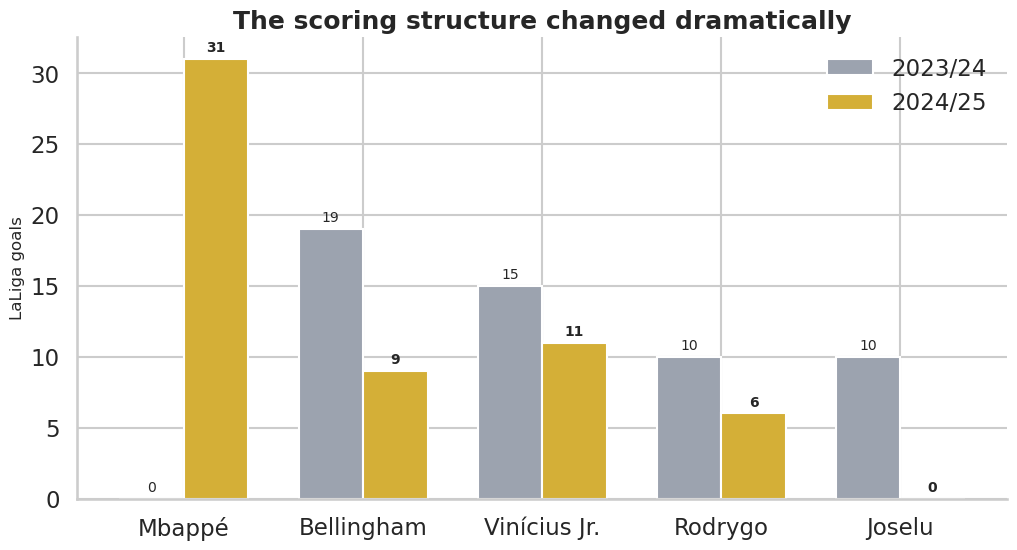

In [9]:
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(player_goals))
width = 0.36
b1 = ax.bar(x - width/2, player_goals["2023/24"], width, label="2023/24", color=COLORS["grey"])
b2 = ax.bar(x + width/2, player_goals["2024/25"], width, label="2024/25", color=COLORS["gold"])
ax.bar_label(b1, padding=3, fontsize=10)
ax.bar_label(b2, padding=3, fontsize=10, fontweight="bold")
ax.set_xticks(x, player_goals["player"])
ax.set_ylabel("LaLiga goals")
ax.set_title("The scoring structure changed dramatically")
ax.legend(frameon=False)
sns.despine()
plt.show()

In [10]:
pre = df.loc[df["season"] == "2023/24"].iloc[0]
post = df.loc[df["season"] == "2024/25"].iloc[0]

headline = pd.DataFrame({
    "indicator": ["Points", "League goals", "Goals conceded", "Goal difference", "League position", "Major titles"],
    "2023/24": [pre.points, pre.gf, pre.ga, pre.gd, pre.position, pre.major_titles],
    "2024/25": [post.points, post.gf, post.ga, post.gd, post.position, post.major_titles],
})
headline["change"] = headline["2024/25"] - headline["2023/24"]
display(headline)

,indicator,2023/24,2024/25,change
0,Points,95,84,-11
1,League goals,87,78,-9
2,Goals conceded,26,38,12
3,Goal difference,61,40,-21
4,League position,1,2,1
5,Major titles,2,0,-2


In [11]:
mbappe_share = 31 / post.gf
continuing_three_pre = player_goals.loc[player_goals["player"].isin(["Bellingham", "Vinícius Jr.", "Rodrygo"]), "2023/24"].sum()
continuing_three_post = player_goals.loc[player_goals["player"].isin(["Bellingham", "Vinícius Jr.", "Rodrygo"]), "2024/25"].sum()

paradox = pd.DataFrame({
    "measure": [
        "Mbappé share of 2024/25 league goals",
        "Bellingham + Vinícius + Rodrygo goals, 2023/24",
        "Bellingham + Vinícius + Rodrygo goals, 2024/25",
        "Change in total team goals",
    ],
    "value": [mbappe_share, continuing_three_pre, continuing_three_post, post.gf - pre.gf],
})
display(paradox)

print(f"Mbappé scored {mbappe_share:.1%} of Madrid's league goals.")
print(f"The three continuing attackers fell from {continuing_three_pre} to {continuing_three_post} goals.")
print(f"Despite Mbappé's 31 goals, the team total fell by {int(pre.gf - post.gf)} goals.")

,measure,value
0,Mbappé share of 2024/25 league goals,0.397
1,"Bellingham + Vinícius + Rodrygo goals, 2023/24",44.000
2,"Bellingham + Vinícius + Rodrygo goals, 2024/25",26.000
3,Change in total team goals,-9.000


Mbappé scored 39.7% of Madrid's league goals.
The three continuing attackers fell from 44 to 26 goals.
Despite Mbappé's 31 goals, the team total fell by 9 goals.


### First analytical finding

Mbappé did not fail as a scorer. Instead, the distribution of scoring changed: he supplied almost 40% of Madrid's league goals, while the combined output of Bellingham, Vinícius and Rodrygo fell sharply. This suggests a role-redistribution or system-balance question—not a simple lack-of-finishing explanation.

The team also conceded 12 more goals. We therefore need a multidimensional measure of collective performance.

# V. Normalization and the Overall Performance Score

This section places variables on a common 0–1 scale before averaging them. Negative indicators—goals conceded, loss rate and league position—are reversed so that higher is always better.

The index is transparent, but its equal weights are a modelling choice. A later sensitivity analysis tests whether the conclusion survives thousands of alternative weighting schemes.

In [12]:
positive_features = ["ppg", "win_rate", "gf_pg", "gd_pg"]
negative_features = ["ga_pg", "loss_rate", "position"]
score_features = positive_features + negative_features

normalized = pd.DataFrame(index=df.index)
scaler_01 = MinMaxScaler()
normalized[score_features] = scaler_01.fit_transform(df[score_features])
for feature in negative_features:
    normalized[feature] = 1 - normalized[feature]

df["overall_performance_score"] = normalized[score_features].mean(axis=1) * 100
df["historical_rank"] = df["overall_performance_score"].rank(ascending=False, method="min").astype(int)

display(df[["season", "overall_performance_score", "historical_rank", "major_titles"]].sort_values("overall_performance_score", ascending=False))

,season,overall_performance_score,historical_rank,major_titles
9,2023/24,85.372,1,2
2,2016/17,77.354,2,2
0,2014/15,75.933,3,0
1,2015/16,74.034,4,1
5,2019/20,66.417,5,1
7,2021/22,64.012,6,2
6,2020/21,50.620,7,0
10,2024/25,45.891,8,0
8,2022/23,37.299,9,1
3,2017/18,30.508,10,1


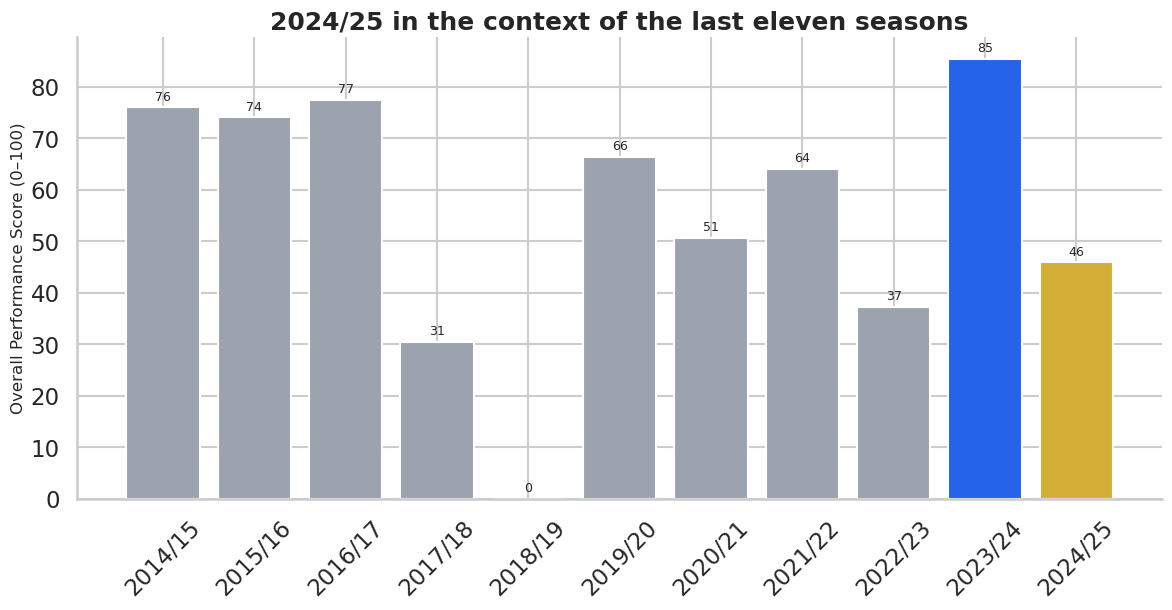

In [13]:
fig, ax = plt.subplots(figsize=(14, 6))
colors = [COLORS["gold"] if s == "2024/25" else COLORS["blue"] if s == "2023/24" else COLORS["grey"] for s in df["season"]]
bars = ax.bar(df["season"], df["overall_performance_score"], color=colors)
ax.bar_label(bars, labels=[f"{v:.0f}" for v in df["overall_performance_score"]], padding=3, fontsize=9)
ax.set_ylabel("Overall Performance Score (0–100)")
ax.set_title("2024/25 in the context of the last eleven seasons")
ax.tick_params(axis="x", rotation=45)
sns.despine()
plt.show()

# VI. Correlations: what tends to move with success?

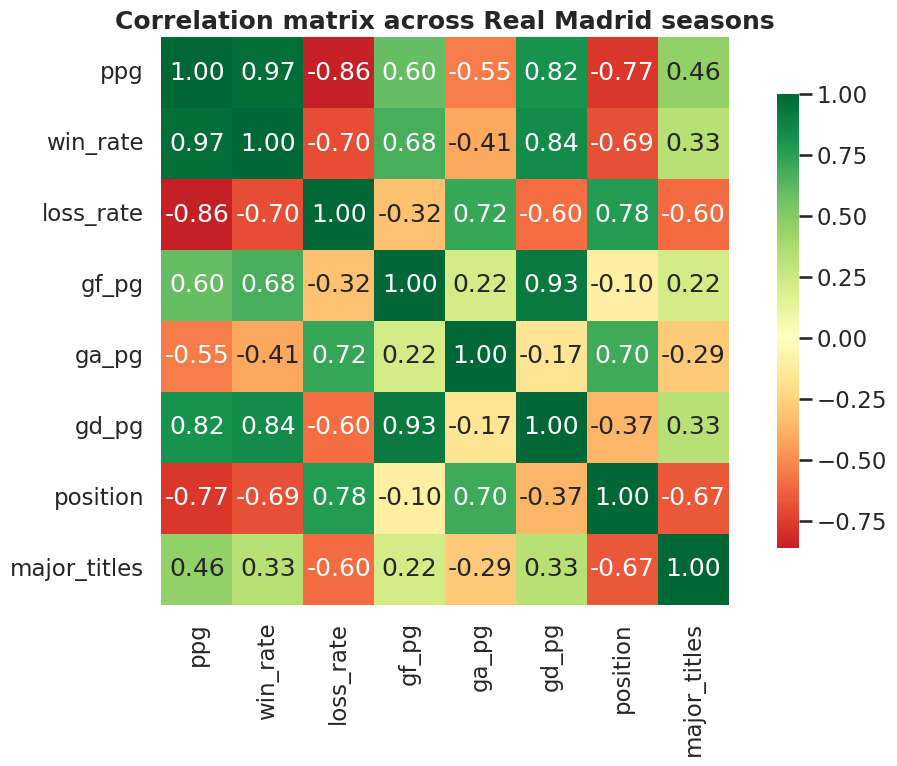

In [14]:
corr_features = ["ppg", "win_rate", "loss_rate", "gf_pg", "ga_pg", "gd_pg", "position", "major_titles"]
corr = df[corr_features].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlGn", center=0, square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation matrix across Real Madrid seasons")
plt.tight_layout()
plt.show()

In [15]:
target_corr = (
    corr["ppg"].drop("ppg").sort_values(key=np.abs, ascending=False).rename("correlation_with_ppg")
)
display(target_corr.to_frame())

,correlation_with_ppg
win_rate,0.966
loss_rate,-0.861
gd_pg,0.816
position,-0.774
gf_pg,0.596
ga_pg,-0.555
major_titles,0.455


### Interpretation

Correlation does not establish causality. It answers a narrower but useful question: in Madrid's recent history, which dimensions have accompanied high points-per-game seasons?

Goals scored and goals conceded should not be interpreted independently. Their combination, goal difference, usually captures the balance between attacking production and defensive control. PCA will now test whether those variables form broader latent dimensions.

# VII. Principal Component Analysis (PCA)

PCA compresses correlated variables into independent components. Here, it helps answer:

- Is there a general **dominance** dimension combining points, wins and goal difference?
- Is there a second dimension separating attack-heavy seasons from defensively controlled seasons?
- Where do 2023/24 and 2024/25 sit in this reduced performance space?

The variables are standardized first because they use different units.

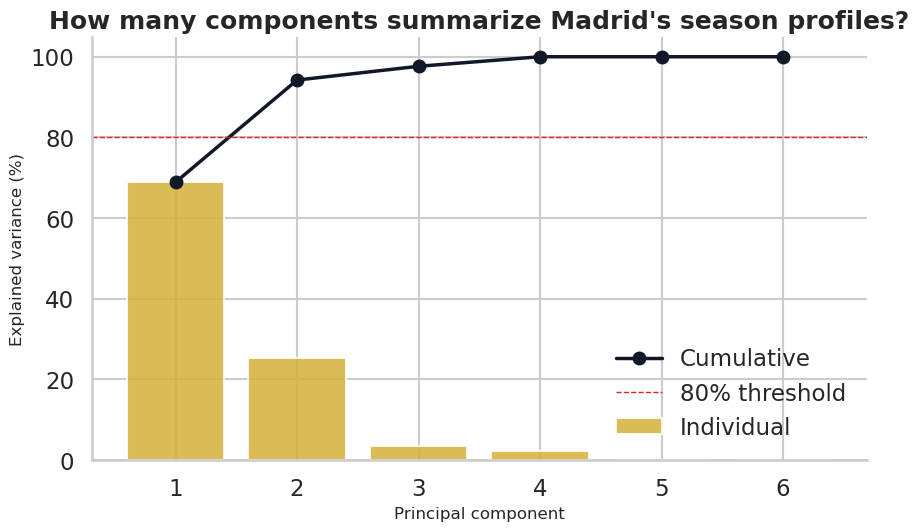

In [16]:
pca_features = ["win_rate", "loss_rate", "gf_pg", "ga_pg", "gd_pg", "ppg"]
X = df[pca_features].copy()
X_scaled = StandardScaler().fit_transform(X)

pca_full = PCA().fit(X_scaled)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

fig, ax1 = plt.subplots(figsize=(10, 5.5))
components = np.arange(1, len(explained) + 1)
ax1.bar(components, explained * 100, color=COLORS["gold"], alpha=0.85, label="Individual")
ax1.plot(components, cumulative * 100, marker="o", color=COLORS["ink"], linewidth=2.5, label="Cumulative")
ax1.axhline(80, color=COLORS["red"], linestyle="--", linewidth=1, label="80% threshold")
ax1.set_xlabel("Principal component")
ax1.set_ylabel("Explained variance (%)")
ax1.set_xticks(components)
ax1.set_title("How many components summarize Madrid's season profiles?")
ax1.legend(frameon=False)
sns.despine()
plt.show()

In [17]:
pca = PCA(n_components=2)
scores = pca.fit_transform(X_scaled)
loadings = pd.DataFrame(
    pca.components_.T,
    index=pca_features,
    columns=["PC1", "PC2"],
)

df["PC1"] = scores[:, 0]
df["PC2"] = scores[:, 1]

display(loadings.round(3))
print(f"PC1 + PC2 explain {pca.explained_variance_ratio_.sum():.1%} of total variance.")

,PC1,PC2
win_rate,0.468,0.043
loss_rate,-0.412,0.346
gf_pg,0.349,0.562
ga_pg,-0.241,0.679
gd_pg,0.446,0.305
ppg,0.482,-0.095


PC1 + PC2 explain 94.2% of total variance.


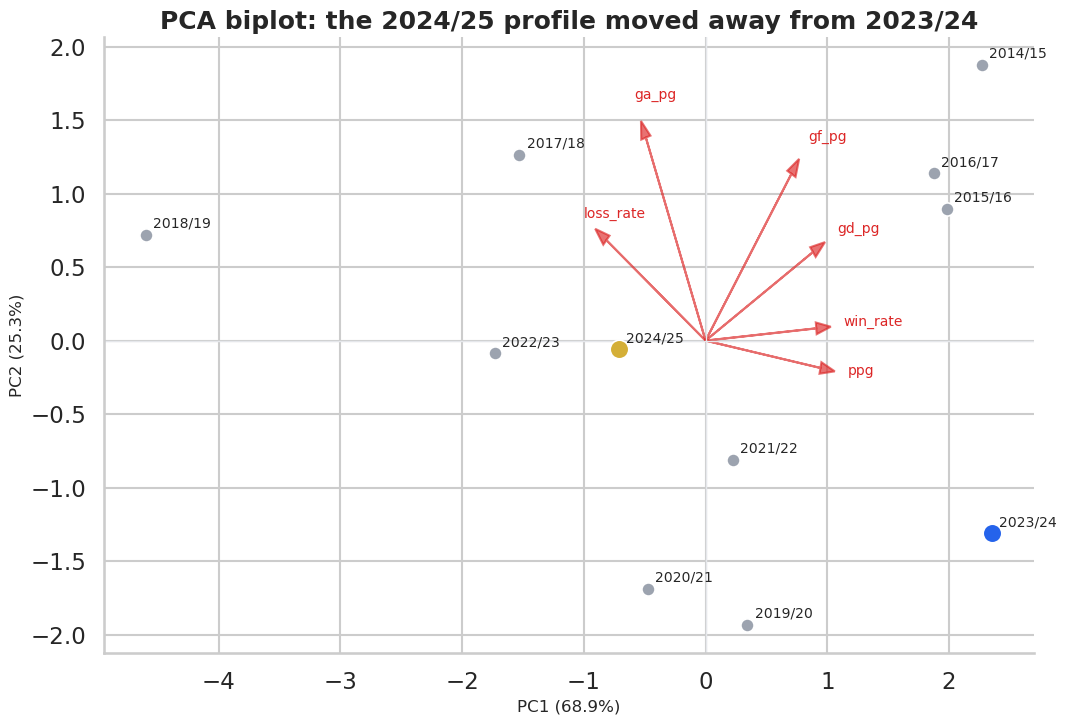

In [18]:
fig, ax = plt.subplots(figsize=(12, 8))
for _, row in df.iterrows():
    color = COLORS["gold"] if row["season"] == "2024/25" else COLORS["blue"] if row["season"] == "2023/24" else COLORS["grey"]
    size = 180 if row["season"] in ["2023/24", "2024/25"] else 90
    ax.scatter(row["PC1"], row["PC2"], s=size, color=color, edgecolor="white", linewidth=1.2, zorder=3)
    ax.text(row["PC1"] + 0.06, row["PC2"] + 0.05, row["season"], fontsize=10)

# Loading arrows show which variables pull seasons in each direction.
scale = 2.2
for feature in pca_features:
    x_arrow, y_arrow = loadings.loc[feature, ["PC1", "PC2"]] * scale
    ax.arrow(0, 0, x_arrow, y_arrow, color=COLORS["red"], alpha=0.65, head_width=0.08, length_includes_head=True)
    ax.text(x_arrow * 1.10, y_arrow * 1.10, feature, color=COLORS["red"], fontsize=10)

ax.axhline(0, color=COLORS["light"], linewidth=1)
ax.axvline(0, color=COLORS["light"], linewidth=1)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title("PCA biplot: the 2024/25 profile moved away from 2023/24")
sns.despine()
plt.show()

### PCA trajectory: isolating the change after 2023/24

The biplot above explains the components; this second view makes the season-to-season movement easier to read. The thin line follows the chronology of Madrid's league seasons, while the blue-to-gold arrow isolates the shift from 2023/24 to 2024/25. A larger distance means a larger change in the overall team profile, not proof that one player caused it.


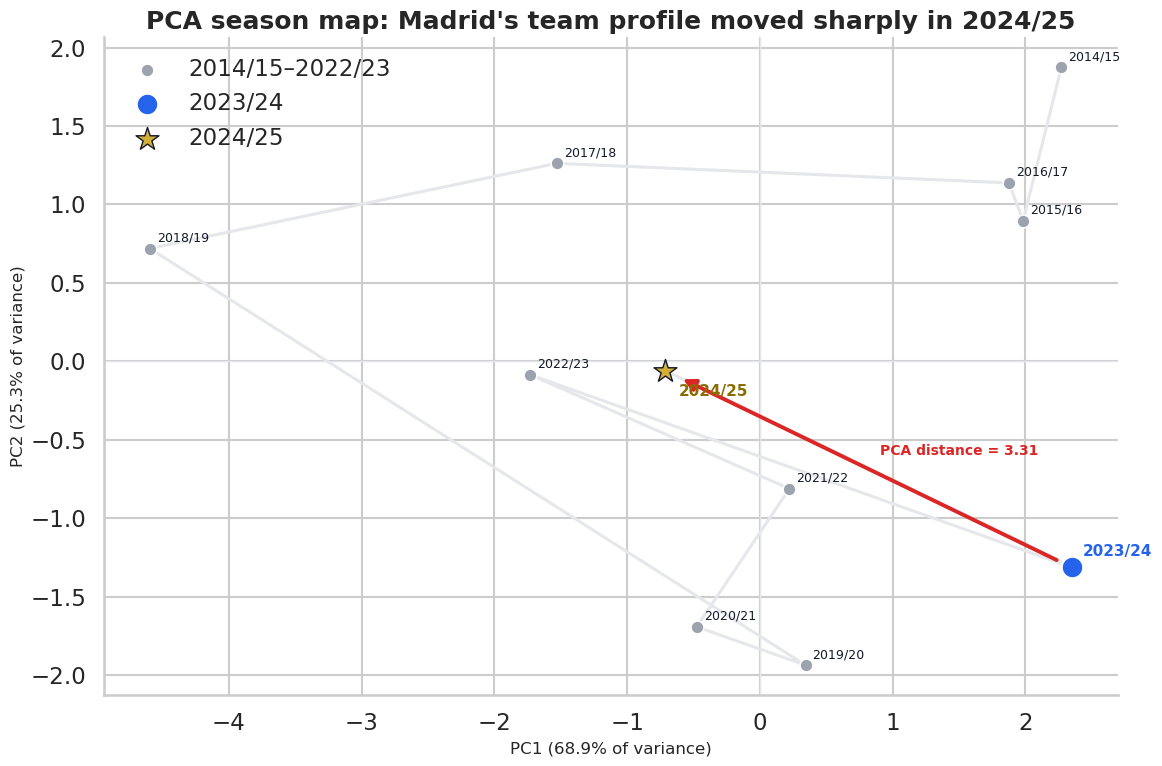

In [19]:
trajectory = df.sort_values("season_order").copy()
before = trajectory[~trajectory["season"].isin(["2023/24", "2024/25"])]
season_2324 = trajectory.loc[trajectory["season"].eq("2023/24")].iloc[0]
season_2425 = trajectory.loc[trajectory["season"].eq("2024/25")].iloc[0]

fig, ax = plt.subplots(figsize=(12, 8))

# A light chronological path gives context without competing with the comparison of interest.
ax.plot(
    trajectory["PC1"], trajectory["PC2"],
    color=COLORS["light"], linewidth=2.2, zorder=1,
)
ax.scatter(
    before["PC1"], before["PC2"],
    s=85, color=COLORS["grey"], edgecolor="white", linewidth=1.1,
    label="2014/15–2022/23", zorder=2,
)
ax.scatter(
    season_2324["PC1"], season_2324["PC2"],
    s=240, color=COLORS["blue"], edgecolor="white", linewidth=1.5,
    label="2023/24", zorder=4,
)
ax.scatter(
    season_2425["PC1"], season_2425["PC2"],
    s=300, marker="*", color=COLORS["gold"], edgecolor=COLORS["ink"], linewidth=1.0,
    label="2024/25", zorder=5,
)

# Emphasize the displacement immediately before and after Mbappé's arrival.
ax.annotate(
    "",
    xy=(season_2425["PC1"], season_2425["PC2"]),
    xytext=(season_2324["PC1"], season_2324["PC2"]),
    arrowprops={"arrowstyle": "-|>", "color": COLORS["red"], "lw": 2.8,
                "mutation_scale": 18, "shrinkA": 12, "shrinkB": 14},
    zorder=3,
)

for _, row in before.iterrows():
    ax.annotate(
        row["season"], (row["PC1"], row["PC2"]),
        xytext=(5, 5), textcoords="offset points", fontsize=9, color=COLORS["ink"],
    )
ax.annotate("2023/24", (season_2324["PC1"], season_2324["PC2"]),
            xytext=(8, 8), textcoords="offset points", fontsize=11,
            color=COLORS["blue"], fontweight="bold")
ax.annotate("2024/25", (season_2425["PC1"], season_2425["PC2"]),
            xytext=(10, -18), textcoords="offset points", fontsize=11,
            color="#8A6D00", fontweight="bold")

shift = float(np.linalg.norm(
    season_2425[["PC1", "PC2"]].to_numpy(dtype=float)
    - season_2324[["PC1", "PC2"]].to_numpy(dtype=float)
))
midpoint = (
    (season_2324["PC1"] + season_2425["PC1"]) / 2,
    (season_2324["PC2"] + season_2425["PC2"]) / 2,
)
ax.annotate(
    f"PCA distance = {shift:.2f}", midpoint,
    xytext=(8, 10), textcoords="offset points", fontsize=10,
    color=COLORS["red"], fontweight="bold",
)

ax.axhline(0, color=COLORS["light"], linewidth=1)
ax.axvline(0, color=COLORS["light"], linewidth=1)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
ax.set_title("PCA season map: Madrid's team profile moved sharply in 2024/25")
ax.legend(frameon=False, loc="best")
sns.despine()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "pca_season_trajectory.png", dpi=180, bbox_inches="tight")
plt.show()


In [20]:
def component_interpretation(column: str) -> pd.DataFrame:
    values = loadings[column].sort_values(key=np.abs, ascending=False)
    return pd.DataFrame({"feature": values.index, "loading": values.values, "absolute_loading": values.abs().values})

display(Markdown("### Variables defining PC1"))
display(component_interpretation("PC1"))
display(Markdown("### Variables defining PC2"))
display(component_interpretation("PC2"))

### Variables defining PC1

,feature,loading,absolute_loading
0,ppg,0.482,0.482
1,win_rate,0.468,0.468
2,gd_pg,0.446,0.446
3,loss_rate,-0.412,0.412
4,gf_pg,0.349,0.349
5,ga_pg,-0.241,0.241


### Variables defining PC2

,feature,loading,absolute_loading
0,ga_pg,0.679,0.679
1,gf_pg,0.562,0.562
2,loss_rate,0.346,0.346
3,gd_pg,0.305,0.305
4,ppg,-0.095,0.095
5,win_rate,0.043,0.043


### PCA interpretation rule

The sign of a principal component is arbitrary; the pattern of loadings is what matters. If points, wins and goal difference move together while losses and goals conceded move in the opposite direction, the component represents broad **collective dominance**. A component contrasting goals scored with goals conceded can be interpreted as **attacking intensity versus defensive control**.

The distance between 2023/24 and 2024/25 is evidence of a different team profile. It is not evidence that Mbappé caused the move.

# VIII. Clustering seasons into performance profiles

PCA maps seasons continuously. Clustering asks whether the seasons naturally form recognizable profiles, such as dominant-balanced, attack-heavy-chaotic or underperforming.

In [21]:
silhouette_rows = []
for k in range(2, 5):
    labels = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE).fit_predict(X_scaled)
    silhouette_rows.append({"clusters": k, "silhouette": silhouette_score(X_scaled, labels)})

silhouettes = pd.DataFrame(silhouette_rows)
display(silhouettes)

best_k = int(silhouettes.loc[silhouettes["silhouette"].idxmax(), "clusters"])
kmeans = KMeans(n_clusters=best_k, n_init=100, random_state=RANDOM_STATE)
df["cluster"] = kmeans.fit_predict(X_scaled)

print(f"Selected number of clusters: {best_k}")

,clusters,silhouette
0,2,0.367
1,3,0.365
2,4,0.362


Selected number of clusters: 2


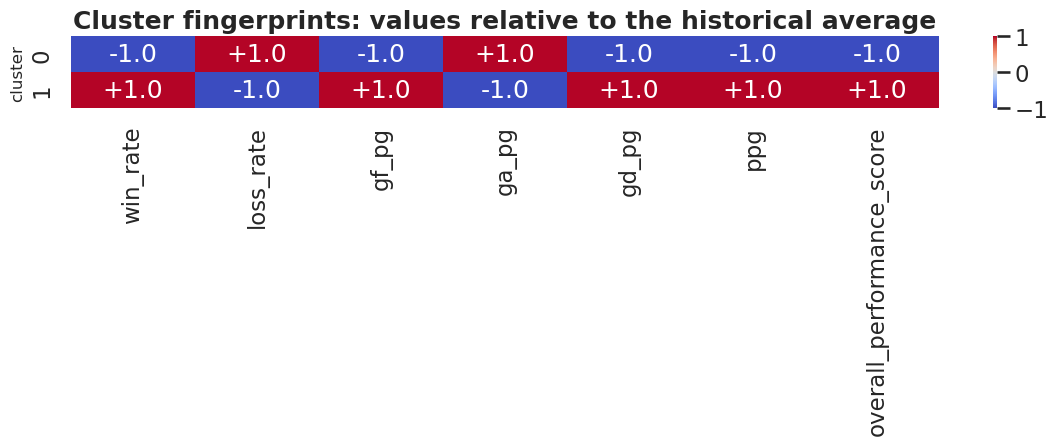

,season,cluster,overall_performance_score,position,major_titles
0,2014/15,1,75.933,2,0
1,2015/16,1,74.034,2,1
2,2016/17,1,77.354,1,2
3,2017/18,0,30.508,3,1
4,2018/19,0,0.000,3,0
5,2019/20,0,66.417,1,1
6,2020/21,0,50.620,2,0
7,2021/22,0,64.012,1,2
8,2022/23,0,37.299,2,1
9,2023/24,1,85.372,1,2


In [22]:
cluster_profiles = df.groupby("cluster")[pca_features + ["overall_performance_score"]].mean()
cluster_profiles_z = pd.DataFrame(
    StandardScaler().fit_transform(cluster_profiles),
    index=cluster_profiles.index,
    columns=cluster_profiles.columns,
)

plt.figure(figsize=(12, 4.8))
sns.heatmap(cluster_profiles_z, annot=True, fmt="+.1f", cmap="coolwarm", center=0)
plt.title("Cluster fingerprints: values relative to the historical average")
plt.tight_layout()
plt.show()

display(df[["season", "cluster", "overall_performance_score", "position", "major_titles"]])

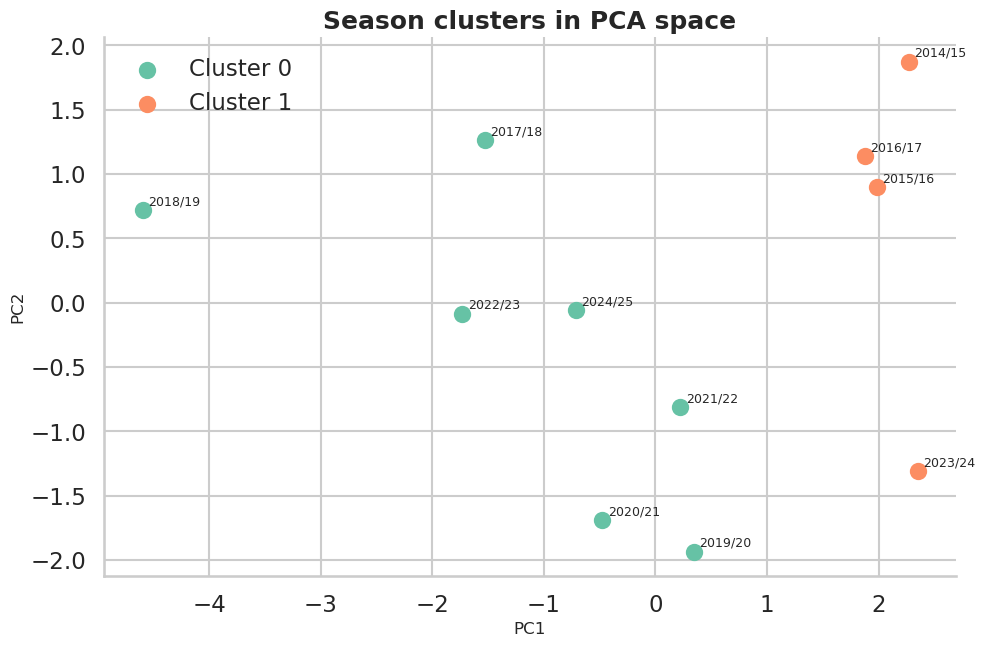

In [23]:
fig, ax = plt.subplots(figsize=(11, 7))
palette = sns.color_palette("Set2", n_colors=best_k)
for cluster, group in df.groupby("cluster"):
    ax.scatter(group["PC1"], group["PC2"], s=120, color=palette[cluster], label=f"Cluster {cluster}")
    for _, row in group.iterrows():
        ax.text(row["PC1"] + 0.05, row["PC2"] + 0.04, row["season"], fontsize=9)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Season clusters in PCA space")
ax.legend(frameon=False)
sns.despine()
plt.show()

# IX. Explanatory models: attack or defence?

The World Happiness project used regressions to rank explanatory factors. Here, the outcome is points per game. The purpose is descriptive: determine whether attacking output or defensive prevention has been more closely associated with Madrid's league performance across the eleven seasons.

With only eleven observations, coefficients are unstable. Leave-one-season-out predictions and regularization reduce overfitting, but do not create causal evidence.

In [24]:
regression_rows = []
for feature in ["gf_pg", "ga_pg", "gd_pg", "win_rate", "loss_rate"]:
    x = df[[feature]].to_numpy()
    y = df["ppg"].to_numpy()
    model = LinearRegression().fit(x, y)
    pred = cross_val_predict(LinearRegression(), x, y, cv=LeaveOneOut())
    regression_rows.append({
        "factor": feature,
        "slope": model.coef_[0],
        "in_sample_r2": model.score(x, y),
        "LOO_MAE": mean_absolute_error(y, pred),
    })

factor_results = pd.DataFrame(regression_rows).sort_values("LOO_MAE")
display(factor_results)

,factor,slope,in_sample_r2,LOO_MAE
3,win_rate,2.714,0.933,0.059
4,loss_rate,-2.369,0.741,0.088
2,gd_pg,0.362,0.666,0.135
0,gf_pg,0.262,0.355,0.159
1,ga_pg,-0.637,0.308,0.183


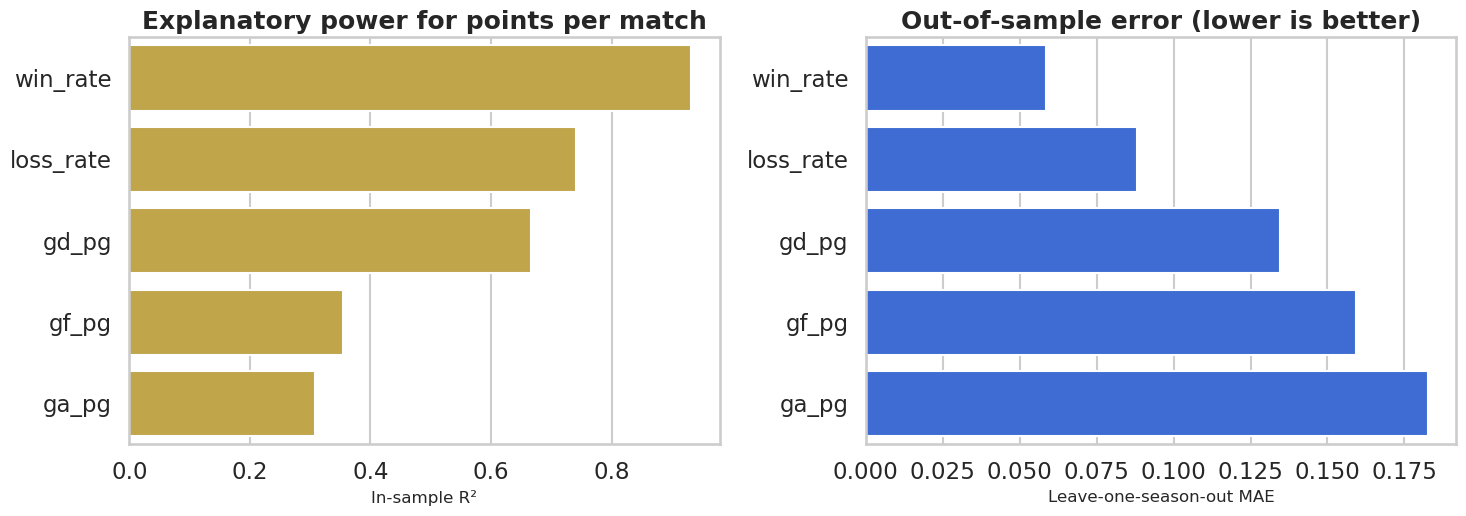

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.barplot(data=factor_results, x="in_sample_r2", y="factor", color=COLORS["gold"], ax=axes[0])
axes[0].set_title("Explanatory power for points per match")
axes[0].set_xlabel("In-sample R²")
axes[0].set_ylabel("")

sns.barplot(data=factor_results, x="LOO_MAE", y="factor", color=COLORS["blue"], ax=axes[1])
axes[1].set_title("Out-of-sample error (lower is better)")
axes[1].set_xlabel("Leave-one-season-out MAE")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [26]:
# Standardized ridge regression lets attacking and defensive coefficients be compared.
X_reg = df[["gf_pg", "ga_pg"]]
y_reg = df["ppg"]
X_reg_scaled = StandardScaler().fit_transform(X_reg)

ridge = RidgeCV(
    alphas=np.logspace(-3, 3, 200),
    cv=LeaveOneOut(),
    scoring="neg_mean_absolute_error",
).fit(X_reg_scaled, y_reg)
ridge_coefficients = pd.Series(ridge.coef_, index=X_reg.columns, name="standardized_coefficient")
display(ridge_coefficients.to_frame())
print(f"Selected ridge alpha: {ridge.alpha_:.3f}")

,standardized_coefficient
gf_pg,0.153
ga_pg,-0.146


Selected ridge alpha: 0.001


# X. Historical nearest neighbours: what season does 2024/25 resemble?

In [27]:
# Euclidean distance in standardized multi-metric space.
target_idx = df.index[df["season"] == "2024/25"][0]
distances = np.linalg.norm(X_scaled - X_scaled[target_idx], axis=1)

neighbours = df[["season", "ppg", "gf_pg", "ga_pg", "gd_pg", "position", "major_titles"]].copy()
neighbours["distance_to_2024_25"] = distances
neighbours = neighbours[neighbours["season"] != "2024/25"].sort_values("distance_to_2024_25")
display(neighbours.head(5))

,season,ppg,gf_pg,ga_pg,gd_pg,position,major_titles,distance_to_2024_25
8,2022/23,2.053,1.974,0.947,1.026,2,1,1.320
7,2021/22,2.263,2.105,0.816,1.289,1,2,1.384
6,2020/21,2.211,1.763,0.737,1.026,2,0,1.791
3,2017/18,2.000,2.474,1.158,1.316,3,1,2.256
5,2019/20,2.289,1.842,0.658,1.184,1,1,2.293


The nearest-neighbour section turns the PCA idea into a concrete comparison. If 2024/25 resembles historically unbalanced or trophy-light seasons more than recent dominant seasons, the problem is collective profile, not the absence of an elite scorer.

# XI. Pinpointing the break: a standardized before/after decomposition

In [28]:
comparison_metrics = ["points", "gf", "ga", "gd", "ppg", "gf_pg", "ga_pg", "gd_pg", "win_rate", "loss_rate"]
historical_sd = df[comparison_metrics].std(ddof=1)
raw_change = post[comparison_metrics] - pre[comparison_metrics]
standardized_change = raw_change / historical_sd

change_table = pd.DataFrame({
    "2023/24": pre[comparison_metrics],
    "2024/25": post[comparison_metrics],
    "raw_change": raw_change,
    "change_in_historical_SD": standardized_change,
})
display(change_table)

,2023/24,2024/25,raw_change,change_in_historical_SD
points,95,84,-11,-1.350
gf,87,78,-9,-0.486
ga,26,38,12,1.691
gd,61,40,-21,-1.144
ppg,2.500,2.211,-0.289,-1.350
gf_pg,2.289,2.053,-0.237,-0.486
ga_pg,0.684,1.000,0.316,1.691
gd_pg,1.605,1.053,-0.553,-1.144
win_rate,0.763,0.684,-0.079,-1.035
loss_rate,0.026,0.158,0.132,1.689


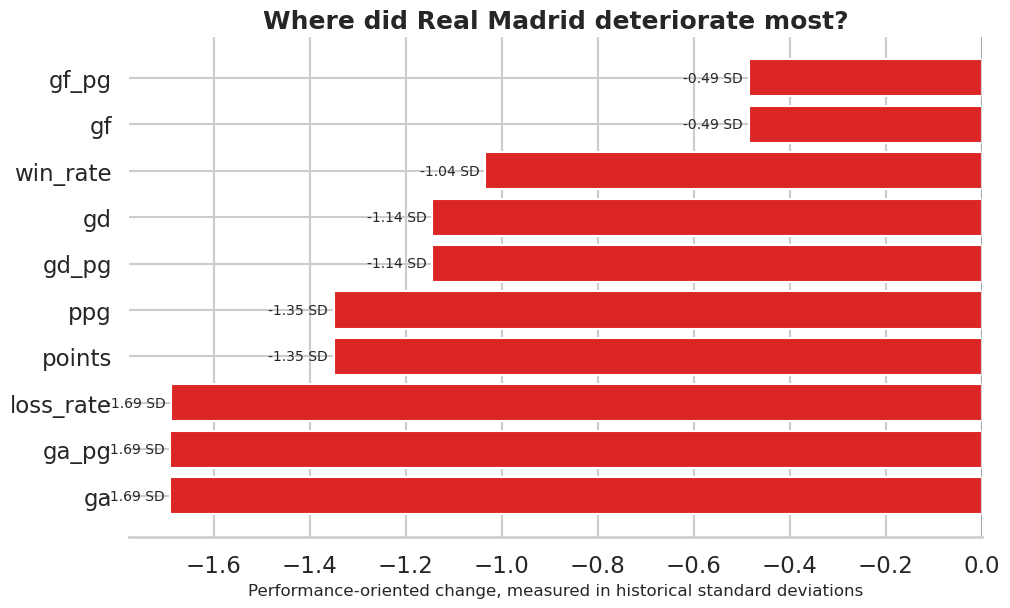

In [29]:
# Orient every change so positive means better performance.
orientation = pd.Series({
    "points": 1, "gf": 1, "ga": -1, "gd": 1, "ppg": 1,
    "gf_pg": 1, "ga_pg": -1, "gd_pg": 1, "win_rate": 1, "loss_rate": -1,
})
oriented = standardized_change * orientation
oriented = oriented.sort_values()

fig, ax = plt.subplots(figsize=(11, 6.5))
bars = ax.barh(oriented.index, oriented.values, color=[COLORS["red"] if v < 0 else COLORS["green"] for v in oriented])
ax.axvline(0, color=COLORS["ink"], linewidth=1)
ax.bar_label(bars, labels=[f"{v:+.2f} SD" for v in oriented], padding=4, fontsize=10)
ax.set_xlabel("Performance-oriented change, measured in historical standard deviations")
ax.set_title("Where did Real Madrid deteriorate most?")
sns.despine(left=True)
plt.show()

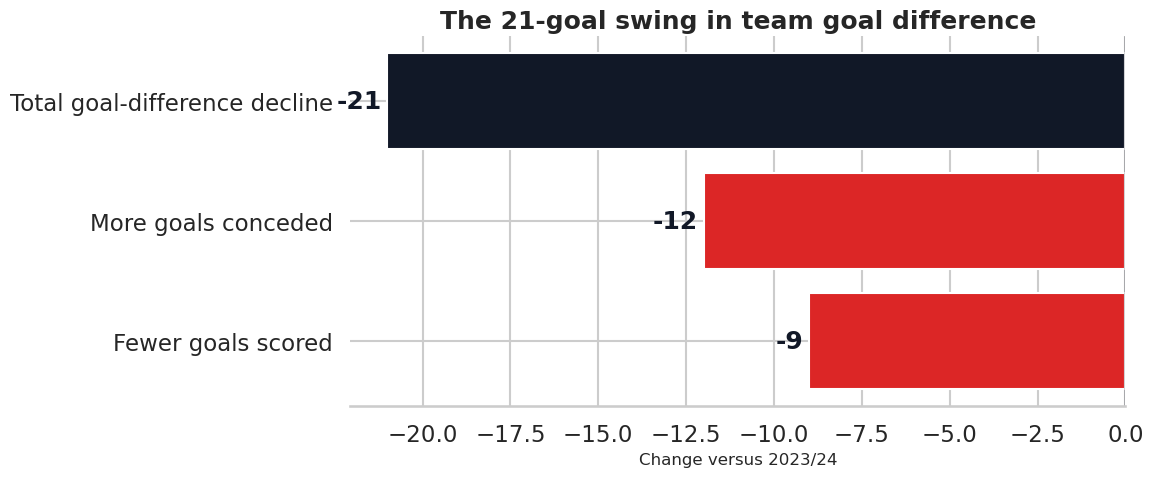

In [30]:
decomposition = pd.DataFrame({
    "component": ["Fewer goals scored", "More goals conceded", "Total goal-difference decline"],
    "goals": [post.gf - pre.gf, -(post.ga - pre.ga), post.gd - pre.gd],
})

fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.barh(decomposition["component"], decomposition["goals"], color=[COLORS["red"], COLORS["red"], COLORS["ink"]])
ax.axvline(0, color=COLORS["ink"], linewidth=1)
ax.bar_label(bars, labels=[f"{v:+.0f}" for v in decomposition["goals"]], padding=4, color=COLORS["ink"], fontweight="bold")
ax.set_title("The 21-goal swing in team goal difference")
ax.set_xlabel("Change versus 2023/24")
sns.despine(left=True)
plt.show()

# XII. Sensitivity analysis: does the index depend on our weights?

In [31]:
rng = np.random.default_rng(RANDOM_STATE)
n_simulations = 10_000
weights = rng.dirichlet(np.ones(len(score_features)), size=n_simulations)
score_matrix = normalized[score_features].to_numpy()
simulated_scores = score_matrix @ weights.T

pre_idx = df.index[df["season"] == "2023/24"][0]
post_idx = df.index[df["season"] == "2024/25"][0]

sensitivity = pd.DataFrame({
    "pre_score": simulated_scores[pre_idx],
    "post_score": simulated_scores[post_idx],
})
sensitivity["post_minus_pre"] = sensitivity["post_score"] - sensitivity["pre_score"]

print(f"Share of 10,000 plausible weighting schemes where 2024/25 beats 2023/24: {(sensitivity['post_minus_pre'] > 0).mean():.2%}")
display(sensitivity["post_minus_pre"].describe(percentiles=[0.025, 0.5, 0.975]).to_frame())

Share of 10,000 plausible weighting schemes where 2024/25 beats 2023/24: 0.00%


,post_minus_pre
count,"10,000.000"
mean,-0.395
std,0.044
min,-0.538
2.5%,-0.476
50%,-0.397
97.5%,-0.302
max,-0.213


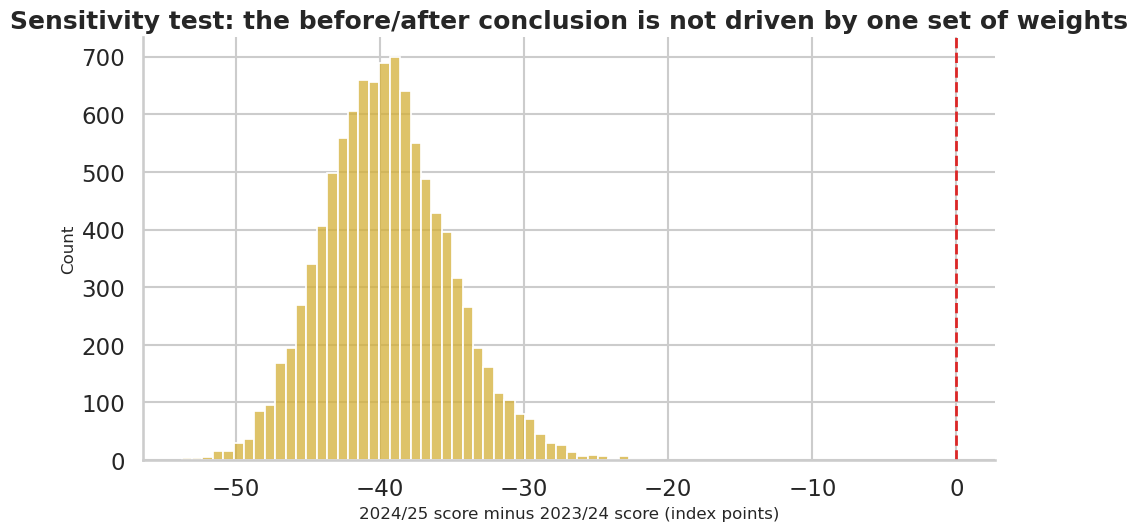

In [32]:
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.histplot(sensitivity["post_minus_pre"] * 100, bins=45, color=COLORS["gold"], ax=ax)
ax.axvline(0, color=COLORS["red"], linestyle="--", linewidth=2)
ax.set_xlabel("2024/25 score minus 2023/24 score (index points)")
ax.set_title("Sensitivity test: the before/after conclusion is not driven by one set of weights")
sns.despine()
plt.show()

# XIII. Competing explanations

## 1. The Kroos control hypothesis

Real Madrid's official 2023/24 statistics record 2,368 LaLiga passes in 2,130 minutes for Toni Kroos, approximately 100 passes per 90 minutes, along with seven assists and 104 recoveries. The issue is not simply replacing a midfielder's goals. It is replacing his volume of circulation, tempo control and progression.

Source: [Toni Kroos 2023/24 official statistics](https://www.realmadrid.com/fr-FR/football/equipe-premiere/effectif/toni-kroos/).

In [33]:
kroos = pd.Series({"matches": 33, "minutes": 2130, "passes": 2368, "assists": 7, "recoveries": 104})
kroos["passes_per_90"] = kroos["passes"] / kroos["minutes"] * 90
display(kroos.to_frame("Kroos, LaLiga 2023/24"))

,"Kroos, LaLiga 2023/24"
matches,33.000
minutes,"2,130.000"
passes,"2,368.000"
assists,7.000
recoveries,104.000
passes_per_90,100.056


## 2. The defensive-availability hypothesis

Carvajal and Militão suffered major knee injuries early in the season. If the largest deterioration appears in goals conceded and defensive dimensions, availability provides a direct mechanism that the “Mbappé problem” narrative ignores.

## 3. The role-concentration hypothesis

Mbappé supplied almost 40% of the league goals, while the other three continuing attackers in the comparison lost 18 goals collectively. This could reflect role overlap, positional changes or a redistribution of shots. It does not mean Mbappé should have scored less; it means the surrounding system created less distributed output.

In [34]:
claims = pd.DataFrame([
    ["Mbappé failed individually", "Contradicted", "31 league goals; Pichichi and European Golden Boot"],
    ["Madrid improved offensively after adding Mbappé", "Contradicted", f"Team goals fell from {int(pre.gf)} to {int(post.gf)}"],
    ["The decline was only attacking", "Contradicted", f"Goals conceded rose from {int(pre.ga)} to {int(post.ga)}"],
    ["The scoring system became concentrated", "Supported", f"Mbappé scored {mbappe_share:.1%} of team league goals"],
    ["Collective balance deteriorated", "Supported", f"Goal difference fell by {int(pre.gd - post.gd)}"],
    ["Mbappé caused the deterioration", "Not identified", "Arrival coincides with Kroos retirement and defensive injuries"],
    ["Loss of midfield control is a plausible mechanism", "Plausible, not proven", "Kroos's high-volume role disappeared at the same break point"],
], columns=["claim", "verdict", "evidence"])
display(claims)

,claim,verdict,evidence
0,Mbappé failed individually,Contradicted,31 league goals; Pichichi and European Golden ...
1,Madrid improved offensively after adding Mbappé,Contradicted,Team goals fell from 87 to 78
2,The decline was only attacking,Contradicted,Goals conceded rose from 26 to 38
3,The scoring system became concentrated,Supported,Mbappé scored 39.7% of team league goals
4,Collective balance deteriorated,Supported,Goal difference fell by 21
5,Mbappé caused the deterioration,Not identified,Arrival coincides with Kroos retirement and de...
6,Loss of midfield control is a plausible mechanism,"Plausible, not proven",Kroos's high-volume role disappeared at the sa...


# XIV. Final conclusion

In [35]:
score_pre = df.loc[df["season"] == "2023/24", "overall_performance_score"].iloc[0]
score_post = df.loc[df["season"] == "2024/25", "overall_performance_score"].iloc[0]
pc_distance = np.linalg.norm(
    df.loc[df["season"] == "2024/25", ["PC1", "PC2"]].to_numpy()
    - df.loc[df["season"] == "2023/24", ["PC1", "PC2"]].to_numpy()
)

points_change = int(post.points - pre.points)
goals_change = int(post.gf - pre.gf)
conceded_change = int(post.ga - pre.ga)
goal_difference_change = int(post.gd - pre.gd)
conceded_pct_change = (post.ga / pre.ga - 1) * 100
pre_ga_pg = pre.ga / pre.played
post_ga_pg = post.ga / post.played

kroos_passes_per_90 = kroos["passes"] / kroos["minutes"] * 90
trio_pre = int(continuing_three_pre)
trio_post = int(continuing_three_post)
trio_change = trio_post - trio_pre

evidence_table = pd.DataFrame([
    {
        "diagnosis": "Loss of midfield control",
        "quantitative finding": (
            f"Kroos supplied {int(kroos['passes']):,} LaLiga passes in "
            f"{int(kroos['minutes']):,} minutes ({kroos_passes_per_90:.1f} per 90), "
            f"plus {int(kroos['assists'])} assists and {int(kroos['recoveries'])} recoveries in 2023/24."
        ),
        "interpretation": "Madrid had to redistribute a very high-volume circulation and progression role.",
    },
    {
        "diagnosis": "Loss of defensive continuity",
        "quantitative finding": (
            f"League goals conceded rose from {int(pre.ga)} to {int(post.ga)} "
            f"(+{conceded_change}; +{conceded_pct_change:.1f}%), or from "
            f"{pre_ga_pg:.2f} to {post_ga_pg:.2f} per match."
        ),
        "interpretation": (
            "This deterioration coincided with Carvajal's multi-ligament knee injury in October 2024 "
            "and Militão's complete ACL rupture with meniscus damage in November 2024."
        ),
    },
    {
        "diagnosis": "Scoring-role concentration",
        "quantitative finding": (
            f"Bellingham fell from 19 to 9 goals (-10), Vinícius from 15 to 11 (-4), "
            f"and Rodrygo from 10 to 6 (-4): {trio_pre} to {trio_post} collectively ({trio_change})."
        ),
        "interpretation": (
            f"Mbappé scored 31 goals ({mbappe_share:.1%} of the team total), yet Madrid's total "
            f"fell from {int(pre.gf)} to {int(post.gf)} ({goals_change})."
        ),
    },
], columns=["diagnosis", "quantitative finding", "interpretation"])

display(Markdown("## Evidence behind each diagnosis"))
display(evidence_table)

## Evidence behind each diagnosis

,diagnosis,quantitative finding,interpretation
0,Loss of midfield control,"Kroos supplied 2,368 LaLiga passes in 2,130 mi...",Madrid had to redistribute a very high-volume ...
1,Loss of defensive continuity,League goals conceded rose from 26 to 38 (+12;...,This deterioration coincided with Carvajal's m...
2,Scoring-role concentration,"Bellingham fell from 19 to 9 goals (-10), Viní...",Mbappé scored 31 goals (39.7% of the team tota...


## 1. Verdict: Mbappé is the visible change, not the best-supported cause

Mbappé's individual output was exceptional, not deficient.
Finding: He scored 31 LaLiga goals, 39.7% of Real Madrid's 78 league goals—and won the Pichichi and European Golden Boot.

Real Madrid nevertheless declined collectively after his arrival.

Finding: Points fell from 95 to 84 (-11), team goals fell from 87 to 78 (-9), goals conceded increased from 26 to 38 (+12), and goal difference fell from +61 to +40 (-21).

The data therefore reject the claim that Mbappé failed as a scorer. They do not identify his arrival as the cause of the collective decline. A more coherent diagnosis is that Madrid added an elite finisher while losing other functions:

Midfield control: Kroos's retirement removed an unusually high-volume organizer and progression source.
Finding: In his final LaLiga season, Kroos completed 2,368 passes in 2,130 minutes, approximately 100.1 passes per 90, with 7 assists and 104 recoveries. The analysis cannot prove that every one of those actions disappeared, but it quantifies the scale of the function that had to be replaced.

Defensive continuity: serious injuries coincided with a major deterioration in defensive output.
Finding: Madrid conceded 38 rather than 26 league goals, an increase of 12 or 46.2%; the rate rose from 0.68 to 1.00 per match. Carvajal suffered an ACL, external collateral ligament and popliteus tendon rupture in October 2024, while Militão suffered a complete ACL rupture with damage to both meniscuses in November. These facts provide a direct alternative mechanism, although season-level data cannot isolate Militão's individual on/off effect.

Role distribution: the attack became more concentrated around Mbappé instead of becoming more productive overall.
Finding: Bellingham declined from 19 to 9 goals (-10), Vinícius from 15 to 11 (-4) and Rodrygo from 10 to 6 (-4). Together they fell from 44 to 26 goals (-18), while Mbappé scored 31. Even after adding those 31 goals, Madrid's team total declined by 9.

The multivariate analysis confirms that this was broader than one player's scoring record.
Finding: The Overall Performance Score fell from 85.4 to 45.9; the first two PCA components explain 94.2% of the variance and place the two seasons 3.31 standardized units apart. Moreover, 0.0% of 10,000 alternative positive weighting schemes ranked 2024/25 above 2023/24.

Answer to the title
Mbappé was not “the problem.” The best-supported diagnosis is a failure to preserve collective balance around him: the team lost a major source of midfield control, suffered severe defensive disruption and concentrated a larger share of its scoring in one player without increasing total output.

This is an evidence-based diagnosis, not definitive causal proof. Player-level event, lineup and tracking data would be required to estimate the individual defensive cost of Militão's absence, quantify role overlap and measure the loss of ball progression directly.

# XV. Exporting the results

In [36]:
df.to_csv(OUTPUT_DIR / "real_madrid_season_analysis.csv", index=False)
player_goals.to_csv(OUTPUT_DIR / "player_goal_comparison.csv", index=False)
loadings.to_csv(OUTPUT_DIR / "pca_loadings.csv")
factor_results.to_csv(OUTPUT_DIR / "regression_factor_results.csv", index=False)
claims.to_csv(OUTPUT_DIR / "claim_scorecard.csv", index=False)
sensitivity["post_minus_pre"].to_csv(OUTPUT_DIR / "index_sensitivity.csv", index=False)

print("Exported evidence tables:")
for path in sorted(OUTPUT_DIR.glob("*.csv")):
    print(" -", path)

Exported evidence tables:
 - outputs/before_after_metric_changes.csv
 - outputs/bootstrap_uncertainty.csv
 - outputs/claim_scorecard.csv
 - outputs/difference_in_differences.csv
 - outputs/index_sensitivity.csv
 - outputs/pca_loadings.csv
 - outputs/player_goal_comparison.csv
 - outputs/real_madrid_season_analysis.csv
 - outputs/real_madrid_season_dashboard.csv
 - outputs/regression_factor_results.csv


## Methodological limitations

- Eleven seasons are enough for an exploratory PCA, not for stable causal inference.
- The composite index reflects transparent but contestable choices; sensitivity analysis addresses weights, not variable selection.
- Goals and points are outcomes, not direct tactical mechanisms.
- Player scoring changes may reflect minutes, injuries, positions and shot allocation.
- Mbappé's arrival, Kroos's retirement and the injury crisis overlap temporally.
- “Blame” is a narrative device. The statistical objective is to locate mechanisms and uncertainty.